# TxGNN — reproduce the paper, end to end

A single notebook that reproduces baseline **TxGNN** (Huang et al., *Nature Medicine*, 2024) on
PrimeKG with the PyTorch-Geometric implementation in `pyg_implementation/`:

| § | stage |
|---|---|
| 0–1 | environment, configuration |
| 2 | PrimeKG + the zero-shot `complex_disease` split |
| 3–5 | model, self-supervised pre-training, fine-tuning |
| 6 | evaluation — edge-level metrics and the paper's disease-centric ranking protocol |
| 7 | inspect the ranked drug list for one held-out disease |
| 8 | **GraphMask explainer** — which edges the model actually used |
| 9 | artifacts |

**What the model is.** A relational graph convolutional encoder over PrimeKG (one weight matrix per
edge type, 2 layers), a DistMult decoder, and a disease-similarity module that pools the embeddings of
mechanistically similar diseases into a prototype — the component that makes zero-shot prediction
possible for a disease with no known drugs.

**Requirements.** A CUDA GPU (the full profile is not practical on CPU), `torch`, `torch_geometric`,
`torch_scatter`, `scikit-learn`, `pandas`, `matplotlib`, and PrimeKG under `data/`.

**Runtime**, single modern GPU, `PROFILE = 'full'`: ~1 min pre-training, ~25 min fine-tuning, ~5 min
disease-centric evaluation, ~40 min GraphMask. Set `PROFILE = 'smoke'` first — it runs the whole
pipeline in a few minutes to prove the plumbing works. **Smoke numbers are meaningless; do not report
them.**


---
## 0 · Environment


In [2]:
# Install once, matched to your torch/CUDA build. Uncomment if needed.
# !pip install torch_geometric
# !pip install torch_scatter -f https://data.pyg.org/whl/torch-2.6.0+cu118.html
# !pip install pandas numpy scikit-learn matplotlib seaborn tqdm


In [3]:
import os, sys, json, time, pickle, random, shutil, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# Locate the repo root, whether this notebook sits at the root or one level down.
def _find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'pyg_implementation' / 'txgnn').is_dir():
            return cand
    raise RuntimeError('Could not find pyg_implementation/txgnn above ' + str(p))

REPO_ROOT = _find_repo_root()
PYG_ROOT  = REPO_ROOT / 'pyg_implementation'

# Put the PyG implementation FIRST on sys.path so `import txgnn` resolves to it.
sys.path.insert(0, str(PYG_ROOT))

# Must be set before torch initialises CUDA. expandable_segments lets the caching
# allocator grow a segment instead of failing on a fragmented pool, which is the usual
# cause of an OOM that appears only after many training steps.
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')

import torch
import txgnn
from txgnn import TxData, TxGNN, TxEval

assert 'pyg_implementation' in txgnn.__file__, (
    'Wrong txgnn package on sys.path (%s). Restart the kernel.' % txgnn.__file__)

# Jupyter caches modules in sys.modules: once `txgnn` has been imported, editing or pulling
# anything under pyg_implementation/txgnn has NO effect until the kernel is restarted, and
# re-running this cell will not tell you. Fail loudly instead of silently running old code.
from txgnn import utils as _tx_utils
assert getattr(_tx_utils, 'TXGNN_PATCH_LEVEL', 0) >= 3, (
    'A stale txgnn is loaded in this kernel (patch level %s, need >= 3). '
    'Restart the kernel and run from the top.' % getattr(_tx_utils, 'TXGNN_PATCH_LEVEL', 0))

print('repo root     :', REPO_ROOT)
print('txgnn package :', txgnn.__file__)


repo root     : /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor
txgnn package : /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor/pyg_implementation/txgnn/__init__.py


In [4]:
import torch_geometric, torch_scatter, sklearn

print('python          :', platform.python_version(), '|', platform.platform())
print('torch           :', torch.__version__)
print('torch_geometric :', torch_geometric.__version__)
print('torch_scatter   :', torch_scatter.__version__)
print('scikit-learn    :', sklearn.__version__)
print('pandas / numpy  :', pd.__version__, '/', np.__version__)
print('CUDA available  :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('CUDA device     :', torch.cuda.get_device_name(0))
    print('CUDA memory     : %.1f GB' % (torch.cuda.get_device_properties(0).total_memory / 1e9))


python          : 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
torch           : 2.6.0+cu118
torch_geometric : 2.8.0
torch_scatter   : 2.1.2+pt26cu118
scikit-learn    : 1.9.0
pandas / numpy  : 3.0.3 / 2.4.4
CUDA available  : True
CUDA device     : NVIDIA GeForce RTX 4060 Ti
CUDA memory     : 16.7 GB


In [5]:
def set_all_seeds(seed: int):
    '''Seed every RNG on the training path.'''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)
if DEVICE == 'cpu':
    print('WARNING: CPU-only. Use PROFILE = "smoke"; the full profile is impractical here.')


device: cuda:0


---
## 1 · Configuration

The model block below is the published baseline. Two knobs are worth understanding because they are
what makes this TxGNN rather than a plain R-GCN:

- **`proto = True`** turns on the disease-similarity module. For a query disease, the model builds a
  *signature* (a binary vector over its disease and protein neighbours), finds the `proto_num` most
  similar diseases, pools their embeddings into a prototype, and mixes it into the query disease's own
  embedding. With `proto = False` you get a plain relational GNN.
- **`agg_measure = 'rarity'`** sets how much prototype to mix in: `c_i = 0.7·exp(-0.7·deg_i) + 0.2`,
  where `deg_i` is the disease's drug-disease degree. A disease with few known drugs leans on its
  neighbours; a well-studied one leans on itself.


In [6]:
PROFILE = 'full'            # <<< 'smoke' to validate the pipeline, 'full' to reproduce
SPLIT   = 'complex_disease'  # the zero-shot protocol: held-out diseases have no drug edges at all
SEED    = 3

# ── model: the published baseline ───────────────────────────────────────────────
MODEL_CFG = dict(
    n_inp       = 100,                 # input / hidden / output width of the encoder
    n_hid       = 100,
    n_out       = 100,
    proto       = True,                # disease-similarity metric learning (see above)
    proto_num   = 3,                   # how many similar diseases to pool
    attention   = False,               # True => the attention variant ("TxGAT")
    sim_measure = 'all_nodes_profile', # signature = neighbours over disease + gene/protein
    agg_measure = 'rarity',            # prototype mixing weight, degree-dependent
)

_PROFILES = {
    'smoke': dict(
        pretrain  = dict(n_epoch=0,    learning_rate=1e-3, batch_size=1024, train_print_per_n=50),
        finetune  = dict(n_epoch=20,   learning_rate=5e-4, train_print_per_n=5, valid_per_n=10),
        evaluate  = dict(n_diseases=5, simulate_random=False),
        explainer = dict(epochs_per_layer=20,   valid_per_n=10,
                         gate_hidden_size=32, no_base=False, amp=False),
    ),
    'full': dict(
        pretrain  = dict(n_epoch=1,    learning_rate=1e-3, batch_size=1024, train_print_per_n=500),
        finetune  = dict(n_epoch=1000, learning_rate=5e-4, train_print_per_n=100, valid_per_n=20),
        evaluate  = dict(n_diseases=None, simulate_random=True),  # None => every test disease
        explainer = dict(epochs_per_layer=1000, valid_per_n=20,
                         gate_hidden_size=32, no_base=False, amp=False),
    ),
}
assert PROFILE in _PROFILES

CFG = dict(profile=PROFILE, split=SPLIT, seed=SEED, device=DEVICE,
           model=MODEL_CFG, **_PROFILES[PROFILE])

RUN_EXPLAINER = True         # §8 — GraphMask. Set False to skip (it is the slowest stage).

# ── paths ───────────────────────────────────────────────────────────────────────
DATA_FOLDER = REPO_ROOT / 'data'
RUN_NAME    = f'TxGNN_{SPLIT}_seed{SEED}_{PROFILE}'
RESULT_DIR  = REPO_ROOT / 'results' / RUN_NAME
MODEL_DIR   = REPO_ROOT / 'saved_models' / RUN_NAME
RESULT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(json.dumps({k: v for k, v in CFG.items() if k != 'model'}, indent=2, default=str))
print('\nmodel   :', MODEL_CFG)
print('results :', RESULT_DIR)
print('models  :', MODEL_DIR)


{
  "profile": "full",
  "split": "complex_disease",
  "seed": 3,
  "device": "cuda:0",
  "pretrain": {
    "n_epoch": 1,
    "learning_rate": 0.001,
    "batch_size": 1024,
    "train_print_per_n": 500
  },
  "finetune": {
    "n_epoch": 1000,
    "learning_rate": 0.0005,
    "train_print_per_n": 100,
    "valid_per_n": 20
  },
  "evaluate": {
    "n_diseases": null,
    "simulate_random": true
  },
  "explainer": {
    "epochs_per_layer": 1000,
    "valid_per_n": 20
  }
}

model   : {'n_inp': 100, 'n_hid': 100, 'n_out': 100, 'proto': True, 'proto_num': 3, 'attention': False, 'sim_measure': 'all_nodes_profile', 'agg_measure': 'rarity'}
results : /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor/results/TxGNN_complex_disease_seed3_full
models  : /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor/saved_models/TxGNN_complex_disease_seed3_full


---
## 2 · Data — PrimeKG and the zero-shot split

PrimeKG holds ~129k nodes over 10 types (drug, disease, gene/protein, anatomy, phenotype, biological
process, molecular function, cellular component, pathway, exposure) and ~8.1M relationship rows over
30 relation names.

The three relations being predicted are `indication`, `contraindication` and `off-label use`.

On the first run, `prepare_split` preprocesses the graph and writes the split to disk (10–30 min); every
later run just loads the cache.


In [7]:
PRIMEKG_DIR = DATA_FOLDER / 'kg'
DATA_FOLDER.mkdir(parents=True, exist_ok=True)

def _link_or_copy(src: Path, dst: Path):
    if dst.exists():
        print(f'  present   {dst.name}'); return
    if not src.exists():
        print(f'  MISSING   {src}  -> TxData will download it'); return
    try:
        os.link(src, dst); how = 'hardlink'
    except OSError:
        shutil.copyfile(src, dst); how = 'copy'
    print(f'  {how:9s} {dst.name}')

def _to_tsv(src: Path, dst: Path):
    if dst.exists():
        print(f'  present   {dst.name}'); return
    if not src.exists():
        print(f'  MISSING   {src}  -> TxData will download it'); return
    pd.read_csv(src, low_memory=False).to_csv(dst, sep='\t', index=False)
    print(f'  tsv       {dst.name}  (the splitter reads sep="\\t")')

print('Wiring PrimeKG into', DATA_FOLDER)
_link_or_copy(PRIMEKG_DIR / 'kg.csv',    DATA_FOLDER / 'kg.csv')
_link_or_copy(PRIMEKG_DIR / 'edges.csv', DATA_FOLDER / 'edges.csv')
_to_tsv      (PRIMEKG_DIR / 'nodes.csv', DATA_FOLDER / 'node.csv')


Wiring PrimeKG into /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor/data
  present   kg.csv
  present   edges.csv
  present   node.csv


In [8]:
set_all_seeds(SEED)

t0 = time.time()
txdata = TxData(data_folder_path=str(DATA_FOLDER))
txdata.prepare_split(split=CFG['split'], seed=CFG['seed'], no_kg=False)
print('\nprepare_split took %.1f s' % (time.time() - t0))


Found local copy...
Found local copy...
Found local copy...
Found saved processed KG... Loading...
Splits detected... Loading splits....
Creating PyG graph....
Done!

prepare_split took 6.1 s


In [9]:
G = txdata.G

node_tbl = pd.DataFrame([(nt, G[nt].num_nodes) for nt in G.node_types],
                        columns=['node_type', 'num_nodes']).sort_values('num_nodes', ascending=False)

edge_tbl = pd.DataFrame([(s, r, d, G[(s, r, d)].num_edges) for s, r, d in G.edge_types],
                        columns=['src_type', 'relation', 'dst_type', 'num_edges']
                        ).sort_values('num_edges', ascending=False)

print('nodes: %s across %d types | edges: %s across %d edge types\n'
      % (f'{node_tbl.num_nodes.sum():,}', len(node_tbl),
         f'{edge_tbl.num_edges.sum():,}', len(edge_tbl)))
display(node_tbl.reset_index(drop=True))
display(edge_tbl.reset_index(drop=True))


nodes: 129,312 across 10 types | edges: 6,734,360 across 50 edge types



,node_type,num_nodes
0,biological_process,28642
1,gene/protein,27610
2,disease,17080
3,effect/phenotype,15311
4,anatomy,14033
5,molecular_function,11169
6,drug,7957
7,cellular_component,4176
8,pathway,2516
9,exposure,818


,src_type,relation,dst_type,num_edges
0,drug,drug_drug,drug,2221622
1,gene/protein,anatomy_protein_present,anatomy,1262006
2,anatomy,rev_anatomy_protein_present,gene/protein,1262006
3,gene/protein,protein_protein,gene/protein,533786
4,disease,disease_phenotype_positive,effect/phenotype,124951
5,effect/phenotype,rev_disease_phenotype_positive,disease,124951
6,biological_process,rev_bioprocess_protein,gene/protein,120369
7,gene/protein,bioprocess_protein,biological_process,120369
8,biological_process,bioprocess_bioprocess,biological_process,87924
9,gene/protein,cellcomp_protein,cellular_component,69328


In [10]:
DD_REL     = ['contraindication', 'indication', 'off-label use']
DD_REV_REL = ['rev_' + r for r in DD_REL]
DD_ETYPES  = ([('drug', r, 'disease') for r in DD_REL]
              + [('disease', r, 'drug') for r in DD_REV_REL])

split_tbl = pd.DataFrame({
    name: {
        'edges (all relations)' : len(df),
        'drug-disease edges'    : int(df.relation.isin(DD_REL + DD_REV_REL).sum()),
        'distinct diseases'     : int(df[df.relation.isin(DD_REL)].y_idx.nunique()),
        'distinct drugs'        : int(df[df.relation.isin(DD_REL)].x_idx.nunique()),
    }
    for name, df in [('train', txdata.df_train), ('valid', txdata.df_valid), ('test', txdata.df_test)]
}).T
display(split_tbl)

for rel in DD_REL:
    print('%-20s train %7d | valid %6d | test %6d' % (
        rel,
        int((txdata.df_train.relation == rel).sum()),
        int((txdata.df_valid.relation == rel).sum()),
        int((txdata.df_test.relation  == rel).sum())))


,edges (all relations),drug-disease edges,distinct diseases,distinct drugs
train,6734360,71698,1707,2040
valid,962616,10804,244,1234
test,403522,2760,103,737


contraindication     train   25789 | valid   4177 | test    709
indication           train    7917 | valid    929 | test    542
off-label use        train    2143 | valid    296 | test    129


### 2.1 Is the split really zero-shot?

Under `complex_disease`, a test disease must have **no** drug-disease edge anywhere in train or valid —
that is the whole point of the protocol. Worth asserting rather than assuming, because if it leaks,
every number below is optimistic.


In [11]:
tr_val = pd.concat([txdata.df_train, txdata.df_valid])
train_dd = set(tr_val[tr_val.relation.isin(DD_REL)].y_idx.unique())
test_dd  = set(txdata.df_test[txdata.df_test.relation.isin(DD_REL)].y_idx.unique())
overlap  = train_dd & test_dd

print('diseases with drug edges in train+valid : %d' % len(train_dd))
print('diseases with drug edges in test        : %d' % len(test_dd))
print('overlap                                 : %d' % len(overlap))

if CFG['split'] == 'complex_disease':
    assert not overlap, 'complex_disease split is leaking treated diseases into test!'
    print('\nOK — every test disease is unseen as a treatment target. This is the zero-shot setting.')
else:
    print('\nSplit is "%s"; overlap above may be expected for non-zero-shot protocols.' % CFG['split'])


diseases with drug edges in train+valid : 1951
diseases with drug edges in test        : 103
overlap                                 : 0

OK — every test disease is unseen as a treatment target. This is the zero-shot setting.


---
## 3 · Build the model

`model_initialize` also precomputes the disease-similarity matrices used by the prototype module. Those
are dense and are the main fixed memory cost here, so their sizes are printed.


In [12]:
set_all_seeds(SEED)

t0 = time.time()
model = TxGNN(data=txdata,
              weight_bias_track=False,      # True + configured wandb to log there
              proj_name='TxGNN',
              exp_name=RUN_NAME,
              device=DEVICE)
model.model_initialize(**CFG['model'])
print('\nmodel_initialize took %.1f s' % (time.time() - t0))

n_params = sum(p.numel() for p in model.model.parameters())
print('parameters : %s' % f'{n_params:,}')
print('\nsimilarity matrices:')
for et, sim in model.model.pred.sim_all_etypes.items():
    print('   %-46s %s  (%.0f MB)' % (str(et), tuple(sim.shape), sim.numel() * 4 / 1e6))



model_initialize took 2.5 s
parameters : 1,015,000

similarity matrices:
   ('drug', 'contraindication', 'disease')        (994, 994)  (4 MB)
   ('drug', 'indication', 'disease')              (1145, 1145)  (5 MB)
   ('drug', 'off-label use', 'disease')           (628, 628)  (2 MB)
   ('disease', 'rev_contraindication', 'drug')    (994, 994)  (4 MB)
   ('disease', 'rev_indication', 'drug')          (1145, 1145)  (5 MB)
   ('disease', 'rev_off-label use', 'drug')       (628, 628)  (2 MB)


---
## 4 · Pre-training (self-supervised)

One epoch of link prediction over **all** edge types. This is where knowledge-graph structure is
loaded into the node representations; fine-tuning afterwards only sees the drug-disease relations.


In [37]:
if CFG['pretrain']['n_epoch'] > 0:
    set_all_seeds(SEED)
    t0 = time.time()
    model.pretrain(**CFG['pretrain'])
    pretrain_s = time.time() - t0
    print('\npre-training took %.1f min' % (pretrain_s / 60))

    model.save_model(str(MODEL_DIR / 'pretrained'))
    print('checkpoint ->', MODEL_DIR / 'pretrained')
else:
    pretrain_s = 0.0
    print('PRE-TRAINING SKIPPED (n_epoch = 0) — this is the smoke profile.')
    print('Fine-tuning will start from random encoder weights. Do not report these numbers.')


Creating minibatch pretraining dataloader...


KeyboardInterrupt: 

Already have a checkpoint? Skip §4–§5 and load it instead of retraining:

```python
set_all_seeds(SEED)                     # <- required, see below
model = TxGNN(data=txdata, weight_bias_track=False, device=DEVICE)
model.load_pretrained(str(MODEL_DIR))   # or MODEL_DIR/'pretrained' for the pre-trained-only weights
```

**The seed call is not optional.** `load_pretrained` re-runs `model_initialize`, whose first act is
`initialize_node_embedding` — the input node features are *frozen random* vectors drawn from the torch
RNG, not learned parameters, so they are not in `model.pt`. Reloading without reseeding gives the
trained weights a different input basis and the metrics silently collapse. Seeding immediately before
the call reproduces the exact features the checkpoint was trained on, because nothing else in
`model_initialize` touches the RNG first.


---
## 5 · Fine-tuning

Trains on the three drug-disease relations, validating every `valid_per_n` epochs and keeping the best
checkpoint in `model.best_model` — which is what every evaluation below uses.


In [ ]:
set_all_seeds(SEED)
t0 = time.time()
model.finetune(**CFG['finetune'],
               save_name=str(RESULT_DIR / 'finetune_valid_metrics.pkl'))
finetune_s = time.time() - t0
print('\nfine-tuning took %.1f min' % (finetune_s / 60))


Epoch: 0 LR: 0.00050 Loss 0.7411, Train Micro AUROC 0.5061 Train Micro AUPRC 0.5288 Train Macro AUROC 0.5100 Train Macro AUPRC 0.5272
----- AUROC Performance in Each Relation -----
('drug', 'contraindication', 'disease'): 0.3985285756528798
('drug', 'indication', 'disease'): 0.5124494149856421
('drug', 'off-label use', 'disease'): 0.4467010956463534
('disease', 'rev_contraindication', 'drug'): 0.5999835678070362
('disease', 'rev_indication', 'drug'): 0.6140721559375439
('disease', 'rev_off-label use', 'drug'): 0.4884563769788189
----- AUPRC Performance in Each Relation -----
('drug', 'contraindication', 'disease'): 0.4258227636713322
('drug', 'indication', 'disease'): 0.544742450041291
('drug', 'off-label use', 'disease'): 0.49239605588282426
('disease', 'rev_contraindication', 'drug'): 0.5911736215534189
('disease', 'rev_indication', 'drug'): 0.5943423237168989
('disease', 'rev_off-label use', 'drug'): 0.5148165892462189
----------------------------------------------
Validation.....
E

In [ ]:
model.save_model(str(MODEL_DIR))

run_info = {
    'config'          : CFG,
    'run_name'        : RUN_NAME,
    'n_params'        : int(n_params),
    'pretrain_seconds': round(pretrain_s, 1),
    'finetune_seconds': round(finetune_s, 1),
    'torch'           : torch.__version__,
    'pyg'             : torch_geometric.__version__,
    'device'          : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
}
with open(RESULT_DIR / 'run_config.json', 'w') as f:
    json.dump(run_info, f, indent=2, default=str)

print('model  ->', MODEL_DIR, '  (model.pt + config.pkl)')
print('config ->', RESULT_DIR / 'run_config.json')
print('\nreload later:  m = TxGNN(data=txdata, device=DEVICE); m.load_pretrained(str(MODEL_DIR))')


model  -> /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor/saved_models/TxGNN_complex_disease_seed3_full   (model.pt + config.pkl)
config -> /home/dsls/Desktop/projects/BardiaSabbagh/txgnn-refactor/results/TxGNN_complex_disease_seed3_full/run_config.json

reload later:  m = TxGNN(data=txdata, device=DEVICE); m.load_pretrained(str(MODEL_DIR))


In [13]:
set_all_seeds(SEED)
model = TxGNN(data=txdata, weight_bias_track=False, device=DEVICE)
model.load_pretrained(str(MODEL_DIR))

---
## 6 · Evaluation

Two protocols, and they answer different questions — report both.

**6.1 Edge-level.** One sampled negative per positive, so the model picks between a true pair and a
random one. Cheap, stable, and good for comparing runs. **A random scorer scores 0.500 here**, so read
these AUPRCs against 0.5, never against 0.

**6.2 Disease-centric.** The paper's protocol: for each held-out disease, rank *every* drug and ask
where the true ones land. Much harder, and the numbers look very different — recall and enrichment at
k are the meaningful ones.


### 6.1 Edge-level metrics


In [14]:
from txgnn.utils import evaluate_fb

# HeteroData.to() is in-place and returns self, so this is the same object as model.G
G_dev = model.G.to(DEVICE)
(auroc_rel, auprc_rel, micro_auroc, micro_auprc, macro_auroc, macro_auprc), test_loss, _, _ = \
    evaluate_fb(model.best_model, model.g_test_pos, model.g_test_neg,
                G_dev, model.dd_etypes, DEVICE, return_embed=True, mode='test')

edge_level = pd.DataFrame(
    [(f'{s} --{r}--> {d}', auroc_rel.get((s, r, d), np.nan), auprc_rel.get((s, r, d), np.nan))
     for s, r, d in DD_ETYPES],
    columns=['relation', 'AUROC', 'AUPRC'])
edge_level.loc[len(edge_level)] = ['MICRO (drug-disease)', micro_auroc, micro_auprc]
edge_level.loc[len(edge_level)] = ['MACRO (drug-disease)', macro_auroc, macro_auprc]

edge_level.to_csv(RESULT_DIR / 'edge_level_test_metrics.csv', index=False)
print('test BCE loss : %.4f   (chance = ln 2 = %.4f)' % (test_loss, np.log(2)))
print('chance AUPRC  : 0.5000  (one sampled negative per positive)')
display(edge_level.style.format({'AUROC': '{:.4f}', 'AUPRC': '{:.4f}'}))


test BCE loss : 0.5915   (chance = ln 2 = 0.6931)
chance AUPRC  : 0.5000  (one sampled negative per positive)


,relation,AUROC,AUPRC
0,drug --contraindication--> disease,0.7673,0.7429
1,drug --indication--> disease,0.8862,0.8762
2,drug --off-label use--> disease,0.8102,0.7728
3,disease --rev_contraindication--> drug,0.6716,0.6752
4,disease --rev_indication--> drug,0.8363,0.8254
5,disease --rev_off-label use--> drug,0.7804,0.7752
6,MICRO (drug-disease),0.7810,0.7712
7,MACRO (drug-disease),0.7920,0.7780


### 6.2 Disease-centric ranking — the paper's protocol

`eval_disease_centric` scores every drug for each held-out disease and returns one row per disease with
AUROC, AUPRC, `Recall@{1%,5%,10%}`, `Recall@{10,50,100}`, `MRR@k`, `AP@k` and `Enrichment@k`, plus the
random baseline at each cutoff.


In [15]:
tx_eval = TxEval(model=model)

t0 = time.time()
if CFG['evaluate']['n_diseases'] is None:
    # full protocol: every test disease, all three relations in one call
    disease_centric = tx_eval.eval_disease_centric(
        disease_idxs    = 'test_set',
        relation        = None,
        save_result     = True,
        save_name       = str(RESULT_DIR / 'disease_centric_eval.pkl'),
        show_plot       = False,
        verbose         = False,
        return_raw      = False,
        simulate_random = CFG['evaluate']['simulate_random'],
    )
else:
    # subset protocol: an explicit disease list requires a single `relation` per call
    disease_centric = {}
    for rel in DD_REL:
        idxs = tx_eval.retrieve_disease_idxs_test_set(rel)[:CFG['evaluate']['n_diseases']]
        print(f'\n=== {rel}: {len(idxs)} diseases ===')
        disease_centric['rev_' + rel] = tx_eval.eval_disease_centric(
            disease_idxs    = list(idxs),
            relation        = rel,
            save_result     = False,
            show_plot       = False,
            verbose         = False,
            return_raw      = False,
            simulate_random = CFG['evaluate']['simulate_random'],
        )
    with open(RESULT_DIR / 'disease_centric_eval.pkl', 'wb') as f:
        pickle.dump(disease_centric, f)

print('\ndisease-centric evaluation took %.1f min' % ((time.time() - t0) / 60))
print('relations      :', list(disease_centric.keys()))
print('table shapes   :', {k: v.shape for k, v in disease_centric.items()})


Evaluating relation: contraindication


  0%|          | 0/53 [00:00<?, ?it/s]

Evaluating relation: indication


  0%|          | 0/66 [00:00<?, ?it/s]

Evaluating relation: off-label use


  0%|          | 0/39 [00:00<?, ?it/s]


disease-centric evaluation took 1.1 min
relations      : ['rev_contraindication', 'rev_indication', 'rev_off-label use']
table shapes   : {'rev_contraindication': (53, 59), 'rev_indication': (66, 59), 'rev_off-label use': (39, 59)}


**One detail that matters when averaging.** The library writes **−1** into the AUROC/AUPRC columns for a
disease left with no positives after the candidate set is intersected. That is a sentinel, not a score,
and averaging it in quietly drags every mean down. `summarise()` below filters it; `drop_sentinels=False`
reproduces the library's own number so you can see the difference.


In [16]:
HEADLINE = ['AUPRC', 'AUROC',
            'Recall@1%', 'Recall@5%', 'Recall@10%', 'Recall@10', 'Recall@50', 'Recall@100',
            'MRR@10', 'MRR@50', 'MRR@100',
            'AP@10', 'AP@50', 'AP@100',
            'Enrichment@1%', 'Enrichment@5%', 'Enrichment@10%',
            'F1', 'Accuracy', 'Sensitivity', 'Specificity', '# of Pos']

def summarise(df, metrics=HEADLINE, drop_sentinels=True):
    '''Mean / std over diseases. drop_sentinels filters the -1 "no positives" placeholder.'''
    rows = {}
    for m in metrics:
        if m not in df.columns:
            continue
        v = pd.to_numeric(df[m], errors='coerce').replace([np.inf, -np.inf], np.nan)
        if drop_sentinels and m != '# of Pos':
            v = v[v != -1]
        v = v.dropna()
        rows[m] = {'mean': v.mean(), 'std': v.std(ddof=0), 'n_diseases': int(v.size)}
    return pd.DataFrame(rows).T


In [17]:
summary_tables = {}
for rel, df in disease_centric.items():
    pretty   = rel.replace('rev_', '')
    raw      = summarise(df, drop_sentinels=False)[['mean']].rename(
                   columns={'mean': 'mean (unfiltered)'})
    filtered = summarise(df, drop_sentinels=True)
    summary_tables[pretty] = filtered.join(raw)

    print(f'\n{"="*78}\n{pretty.upper()}   ({df.shape[0]} test diseases)\n{"="*78}')
    display(summary_tables[pretty]
            .style.format('{:.4f}', subset=['mean', 'std', 'mean (unfiltered)'])
                  .format('{:.0f}', subset=['n_diseases']))

headline = pd.DataFrame({rel: t['mean'] for rel, t in summary_tables.items()})
headline.to_csv(RESULT_DIR / 'disease_centric_summary.csv')

print('\n\nHEADLINE — mean over held-out diseases')
display(headline.loc[[m for m in ['AUROC', 'AUPRC', 'Recall@1%', 'Recall@5%', 'Recall@10%',
                                  'Recall@50', 'MRR@50', 'Enrichment@5%', '# of Pos']
                      if m in headline.index]].style.format('{:.4f}'))



CONTRAINDICATION   (53 test diseases)


,mean,std,n_diseases,mean (unfiltered)
AUPRC,0.1335,0.2377,53,0.1335
AUROC,0.7879,0.2022,53,0.7879
Recall@1%,0.1123,0.2694,53,0.1123
Recall@5%,0.3815,0.3882,53,0.3815
Recall@10%,0.4957,0.3911,53,0.4957
Recall@10,0.1078,0.2688,53,0.1078
Recall@50,0.3339,0.3830,53,0.3339
Recall@100,0.4418,0.3883,53,0.4418
MRR@10,0.1948,0.3569,53,0.1948
MRR@50,0.2067,0.3510,53,0.2067



INDICATION   (66 test diseases)


,mean,std,n_diseases,mean (unfiltered)
AUPRC,0.1785,0.2043,66,0.1785
AUROC,0.8820,0.1922,66,0.8820
Recall@1%,0.3724,0.3849,66,0.3724
Recall@5%,0.5900,0.4174,66,0.5900
Recall@10%,0.7290,0.3712,66,0.7290
Recall@10,0.2543,0.3385,66,0.2543
Recall@50,0.5272,0.4090,66,0.5272
Recall@100,0.5975,0.4191,66,0.5975
MRR@10,0.2614,0.3462,66,0.2614
MRR@50,0.2710,0.3397,66,0.2710



OFF-LABEL USE   (39 test diseases)


,mean,std,n_diseases,mean (unfiltered)
AUPRC,0.1747,0.2881,39,0.1747
AUROC,0.8119,0.2343,39,0.8119
Recall@1%,0.1105,0.2432,39,0.1105
Recall@5%,0.3509,0.4255,39,0.3509
Recall@10%,0.6240,0.4416,39,0.6240
Recall@10,0.1777,0.3239,39,0.1777
Recall@50,0.6240,0.4416,39,0.6240
Recall@100,0.7208,0.3977,39,0.7208
MRR@10,0.2009,0.3792,39,0.2009
MRR@50,0.2188,0.3704,39,0.2188




HEADLINE — mean over held-out diseases


,contraindication,indication,off-label use
AUROC,0.7879,0.8820,0.8119
AUPRC,0.1335,0.1785,0.1747
Recall@1%,0.1123,0.3724,0.1105
Recall@5%,0.3815,0.5900,0.3509
Recall@10%,0.4957,0.7290,0.6240
Recall@50,0.3339,0.5272,0.6240
MRR@50,0.2067,0.2710,0.2188
Enrichment@5%,7.4642,12.1732,7.0478
# of Pos,13.3774,8.2121,3.3077


### 6.3 Distributions across diseases


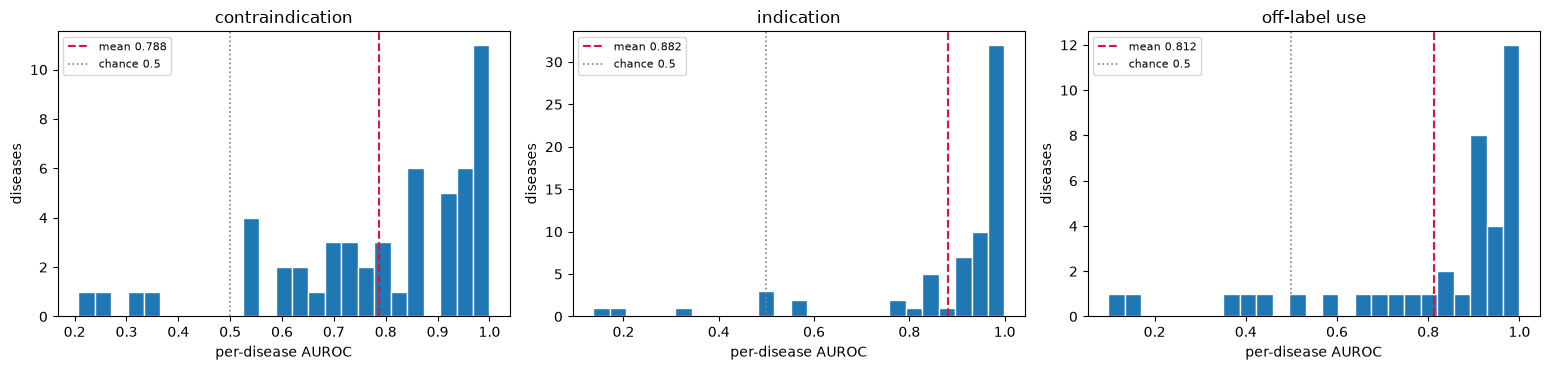

In [18]:
rels = list(summary_tables.keys())
fig, axes = plt.subplots(1, len(rels), figsize=(5.2 * len(rels), 3.8), squeeze=False)
for ax, rel in zip(axes[0], rels):
    v = pd.to_numeric(disease_centric['rev_' + rel]['AUROC'], errors='coerce')
    v = v[(v != -1)].dropna()
    ax.hist(v, bins=25, edgecolor='white')
    ax.axvline(v.mean(), ls='--', lw=1.5, color='crimson',
               label='mean %.3f' % v.mean())
    ax.axvline(0.5, ls=':', lw=1.2, color='grey', label='chance 0.5')
    ax.set_title(rel); ax.set_xlabel('per-disease AUROC'); ax.set_ylabel('diseases')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


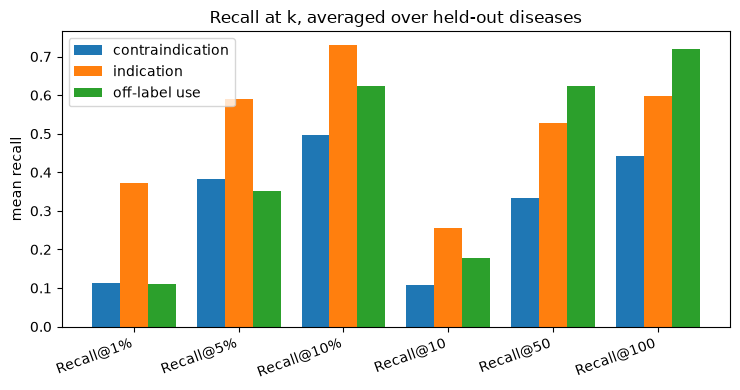

In [19]:
ks = ['Recall@1%', 'Recall@5%', 'Recall@10%', 'Recall@10', 'Recall@50', 'Recall@100']
avail = [k for k in ks if k in headline.index]

fig, ax = plt.subplots(figsize=(7.5, 4))
w = 0.8 / len(rels)
x = np.arange(len(avail))
for i, rel in enumerate(rels):
    ax.bar(x + i * w, headline.loc[avail, rel].values, width=w, label=rel)
ax.set_xticks(x + w * (len(rels) - 1) / 2); ax.set_xticklabels(avail, rotation=20, ha='right')
ax.set_ylabel('mean recall'); ax.set_title('Recall at k, averaged over held-out diseases')
ax.legend(); plt.tight_layout(); plt.show()


---
## 7 · Inspect one held-out disease

The ranked drug list is what the model is actually for. Pick a disease with no known treatments in
training and look at what comes out on top.


In [20]:
maps = txdata.retrieve_id_mapping()   # id2name_drug, id2name_disease, idx2id_disease, idx2id_drug

def disease_name(idx):
    did = maps['idx2id_disease'].get(float(idx))
    return maps['id2name_disease'].get(did, f'<idx {idx}>')

QUERY_RELATION = 'indication'
test_disease_idxs = tx_eval.retrieve_disease_idxs_test_set(QUERY_RELATION)

print('%d held-out diseases for "%s". First 10:' % (len(test_disease_idxs), QUERY_RELATION))
for idx in test_disease_idxs[:10]:
    print('   %10s  %s' % (idx, disease_name(idx)))

QUERY_DISEASE_IDX = float(test_disease_idxs[0])
QUERY_DISEASE_NAME = disease_name(QUERY_DISEASE_IDX)
print('\nquerying:', QUERY_DISEASE_NAME)


66 held-out diseases for "indication". First 10:
      12966.0  restless legs syndrome
      17047.0  inflammatory bowel disease
      14128.0  pemphigus
      12622.0  atopic eczema
       6943.0  adrenal insufficiency
      12900.0  ankylosing spondylitis
       3677.0  localized pagetoid reticulosis
       5541.0  granulomatous slack skin disease
      12964.0  primary ovarian failure
      12774.0  prostate carcinoma

querying: restless legs syndrome


In [21]:
raw = tx_eval.eval_disease_centric(
    disease_idxs    = [QUERY_DISEASE_IDX],
    relation        = QUERY_RELATION,
    save_result     = False,
    show_plot       = False,
    verbose         = False,
    return_raw      = True,     # -> {'prediction': {disease: {drug: score}}, 'label': ...}
    simulate_random = False,
)

did    = list(raw['prediction'].keys())[0]
preds  = raw['prediction'][did]
labels = raw['label'][did]

rank = (pd.DataFrame({'drug_id': list(preds.keys()),
                      'score'  : list(preds.values()),
                      'label'  : [labels[k] for k in preds.keys()]})
          .assign(drug=lambda d: d.drug_id.map(maps['id2name_drug']))
          .query('label != -1')      # -1 == already known in train/valid, not a test item
          .sort_values('score', ascending=False)
          .reset_index(drop=True))
rank.index += 1

print('disease  : %s  (id %s)' % (QUERY_DISEASE_NAME, did))
print('relation : %s | candidates ranked: %d | held-out positives: %d\n'
      % (QUERY_RELATION, len(rank), int((rank.label == 1).sum())))

top = rank.head(25)[['drug', 'score', 'label']].copy()
top['hit'] = np.where(top.label == 1, '*', '')
print('--- top 25 predicted drugs  (* = held-out ground truth) ---')
display(top[['drug', 'score', 'hit']].style.format({'score': '{:.4f}'}))

print('\n--- where the held-out positives actually ranked ---')
display(rank[rank.label == 1][['drug', 'score']].head(20).style.format({'score': '{:.4f}'}))


  0%|          | 0/1 [00:00<?, ?it/s]

disease  : restless legs syndrome  (id 5391.0)
relation : indication | candidates ranked: 7957 | held-out positives: 5

--- top 25 predicted drugs  (* = held-out ground truth) ---


,drug,score,hit
1,Ziconotide,4.7616,
2,Pilsicainide,4.0929,
3,Droperidol,3.9914,
4,Oxycodone,3.9016,
5,Ropivacaine,3.6820,
6,Nabilone,3.6382,
7,Isometheptene,3.4260,
8,Remifentanil,3.4171,
9,Cyclobenzaprine,3.3953,
10,Fentanyl,3.3435,



--- where the held-out positives actually ranked ---


,drug,score
24,Gabapentin,3.0563
208,Gabapentin enacarbil,1.5235
1774,Pramipexole,0.2502
3869,Ropinirole,-0.4894
5331,Rotigotine,-1.2002


---
## 8 · GraphMask — which edges did the model use?

A prediction is only actionable if you can see the evidence behind it. **GraphMask** learns, per edge
and per encoder layer, a gate in {0, 1} that says whether that message can be dropped without changing
the prediction. Training optimises a sparsity penalty subject to staying within `allowance` of the
original output, so what survives is the subgraph the model genuinely relies on.

The output is an importance score in [0, 1] for every edge at each of the two layers.

This is the slowest and by far the most memory-hungry stage, so it is worth knowing the budget
before starting it.

**Where the memory goes.** The gated forward keeps one `(edges x n_hid)` activation per edge type
*per layer* so the gates can be differentiated. With 6.73M edges at `n_hid = 100` a single such
tensor is 2.7 GB, and the gated message needs several of them. GraphMask then trains **one layer at
a time, last layer first**:

| phase | trainable gates | activations retained |
|---|---|---|
| 1 | layer 2 | layer 2 only — layer 1 is frozen upstream, so its graph is never built |
| 2 | layer 1 | **both layers** — layer 2's inputs now depend on a trainable parameter |

So phase 2 needs roughly twice the memory of phase 1. A run that trains happily through all of
phase 1 and then dies on `Enabling layer 0` has not leaked; it has hit this step change.

**Levers, cheapest first.** Each is a knob in `CFG['explainer']`:

1. `PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` — already set in §0. Free, and fixes the OOMs
   that come from fragmentation rather than from a genuine shortfall.
2. `no_base = True` — drops the learned baseline that replaces a masked message, removing one
   full-width tensor per edge type per layer. Changes what a closed gate means (zero instead of a
   learned default), so say so if you report the result.
3. `amp = True` — runs both forwards under bfloat16 autocast, halving activation memory. Losses
   stay in fp32. This is the lever that makes phase 2 fit on a 16 GB card. Gate scores come out
   slightly noisier, so prefer fp32 whenever it fits.
4. `gate_hidden_size` — smaller gate MLPs. The least effective of the four, since the
   `(edges x n_hid)` message tensors dominate, not the gate hidden layer.

`epochs_per_layer` does **not** change peak memory — it only decides how long you sit at the peak.
Lowering it will not rescue an OOM.

Peak usage is printed at every validation step, so you can see which phase you are in and how much
headroom is left. `RUN_EXPLAINER = False` skips the whole section.


### 8.1 Train the gates


In [22]:
if RUN_EXPLAINER:
    # the explainer accepts 'indication', 'contraindication' or 'off-label'
    EXPLAIN_RELATION = 'indication'

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    t0 = time.time()
    gm_metrics = model.train_graphmask(
        relation                   = EXPLAIN_RELATION,
        learning_rate              = 3e-4,
        allowance                  = 0.005,   # how far the masked prediction may drift
        epochs_per_layer           = CFG['explainer']['epochs_per_layer'],
        penalty_scaling            = 1,       # weight on the sparsity penalty
        moving_average_window_size = 100,
        valid_per_n                = CFG['explainer']['valid_per_n'],
        gate_hidden_size           = CFG['explainer']['gate_hidden_size'],
        no_base                    = CFG['explainer']['no_base'],
        amp                        = CFG['explainer']['amp'],
    )
    print('\nGraphMask training took %.1f min' % ((time.time() - t0) / 60))
    if torch.cuda.is_available():
        print('peak GPU memory: %.2f GB of %.2f GB' % (
            torch.cuda.max_memory_allocated() / 1e9,
            torch.cuda.get_device_properties(0).total_memory / 1e9))

    model.save_graphmask_model(str(MODEL_DIR / 'graphmask'))
    with open(RESULT_DIR / f'graphmask_metrics_{EXPLAIN_RELATION}.json', 'w') as f:
        json.dump({k: float(v) for k, v in gm_metrics.items()}, f, indent=2)

    display(pd.Series(gm_metrics).to_frame('value'))
else:
    print('RUN_EXPLAINER is False — skipping GraphMask.')


gate_hidden_size:  32
Enabling layer 1
Running epoch 0 of GraphMask training. Mean divergence=0.0000, mean penalty=1.9051, bce_update=0.2306, bce_original=0.2306, num_masked_l1=0.0000, num_masked_l2=0.0000
----- validation Result -----
Epoch 0, Mean divergence=0.0000, mean penalty=1.9035, bce_update=0.5310, bce_original=0.5310, num_masked_l1=0.0000, num_masked_l2=0.0000
-------------------------------
Running epoch 1 of GraphMask training. Mean divergence=0.0000, mean penalty=1.9043, bce_update=0.2379, bce_original=0.2379, num_masked_l1=0.0000, num_masked_l2=0.0000
Running epoch 2 of GraphMask training. Mean divergence=0.0000, mean penalty=1.9035, bce_update=0.2349, bce_original=0.2349, num_masked_l1=0.0000, num_masked_l2=0.0000
Running epoch 3 of GraphMask training. Mean divergence=0.0000, mean penalty=1.9026, bce_update=0.2300, bce_original=0.2300, num_masked_l1=0.0000, num_masked_l2=0.0000
Running epoch 4 of GraphMask training. Mean divergence=0.0000, mean penalty=1.9018, bce_update

OutOfMemoryError: CUDA out of memory. Tried to allocate 482.00 MiB. GPU 0 has a total capacity of 15.57 GiB of which 402.75 MiB is free. Process 2728 has 122.25 MiB memory in use. Including non-PyTorch memory, this process has 14.92 GiB memory in use. Of the allocated memory 14.40 GiB is allocated by PyTorch, and 379.64 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

### 8.2 Per-edge importance

`retrieve_gates_scores_penalties(relation)` returns gates, scores and penalties for the whole graph and
for the test graph. We keep the whole-graph scores and build a numeric table — one row per edge, with a
layer-1 and layer-2 importance.

Node names are joined on demand rather than for all ~8M rows, which keeps memory reasonable.


In [ ]:
if RUN_EXPLAINER:
    from txgnn.utils import convert2str

    whole_graph, test_graph = model.retrieve_gates_scores_penalties(EXPLAIN_RELATION)
    _, _, _, _, num_masked, gates, scores, penalties = whole_graph

    # numeric edge table (no strings yet).
    # NOTE: PyG's HeteroData.to() mutates the object in place, so `model.G.to('cpu')`
    # would drag the live graph off the GPU. Copy the index tensors instead.
    parts = []
    for (src, rel, dst) in model.G.edge_types:
        if rel not in scores[0] or rel not in scores[1]:
            continue                      # this relation carried no gated messages
        ei = model.G[(src, rel, dst)].edge_index.cpu()
        parts.append(pd.DataFrame({
            'src_type'         : src,
            'relation'         : rel,
            'dst_type'         : dst,
            'x_idx'            : ei[0].numpy(),
            'y_idx'            : ei[1].numpy(),
            'layer1_importance': scores[0][rel].cpu().numpy().reshape(-1),
            'layer2_importance': scores[1][rel].cpu().numpy().reshape(-1),
        }))
    gates_df = pd.concat(parts, ignore_index=True)
    gates_df.to_pickle(RESULT_DIR / f'graphmask_edge_importance_{EXPLAIN_RELATION}.pkl')

    total_edges = len(gates_df)
    print('relation explained : %s' % EXPLAIN_RELATION)
    print('edges scored       : %s' % f'{total_edges:,}')
    print('kept at layer 1    : %.1f%%  (importance > 0.5)' % (100 * (gates_df.layer1_importance > 0.5).mean()))
    print('kept at layer 2    : %.1f%%  (importance > 0.5)' % (100 * (gates_df.layer2_importance > 0.5).mean()))
    print('masked by layer    : %s' % [float(x) for x in num_masked])


In [ ]:
if RUN_EXPLAINER:
    # name lookup built once, used only for the rows we actually display
    df_raw = pd.read_csv(DATA_FOLDER / 'kg.csv', low_memory=False)
    df_raw['x_id'] = df_raw.x_id.apply(convert2str)
    df_raw['y_id'] = df_raw.y_id.apply(convert2str)
    dfm = model.df.copy()
    dfm['x_id'] = dfm.x_id.apply(convert2str)
    dfm['y_id'] = dfm.y_id.apply(convert2str)

    idx2id, id2name = {}, {}
    for nt in model.G.node_types:
        m_ = dict(dfm[dfm.x_type == nt][['x_idx', 'x_id']].values)
        m_.update(dict(dfm[dfm.y_type == nt][['y_idx', 'y_id']].values))
        idx2id[nt] = m_
        n_ = dict(df_raw[df_raw.x_type == nt][['x_id', 'x_name']].values)
        n_.update(dict(df_raw[df_raw.y_type == nt][['y_id', 'y_name']].values))
        id2name[nt] = n_

    def name_of(node_type, idx):
        return id2name.get(node_type, {}).get(idx2id.get(node_type, {}).get(idx), f'<{node_type} {idx}>')

    def with_names(df):
        out = df.copy()
        out['x_name'] = [name_of(t, i) for t, i in zip(out.src_type, out.x_idx)]
        out['y_name'] = [name_of(t, i) for t, i in zip(out.dst_type, out.y_idx)]
        return out[['x_name', 'src_type', 'relation', 'y_name', 'dst_type',
                    'layer1_importance', 'layer2_importance']]

    print('--- 20 most important edges in the graph (layer 2) ---')
    display(with_names(gates_df.nlargest(20, 'layer2_importance'))
            .style.format({'layer1_importance': '{:.3f}', 'layer2_importance': '{:.3f}'}))


### 8.3 Which relation types carry the explanation?

Aggregating importance by relation says where in PrimeKG the evidence lives. `share_kept` is the
fraction of that relation's edges the model keeps — a relation with many edges but a low share is
mostly ignored.


In [ ]:
if RUN_EXPLAINER:
    by_rel = (gates_df.groupby('relation')
              .agg(edges              = ('layer2_importance', 'size'),
                   mean_layer1        = ('layer1_importance', 'mean'),
                   mean_layer2        = ('layer2_importance', 'mean'),
                   share_kept_layer2  = ('layer2_importance', lambda s: (s > 0.5).mean()))
              .sort_values('mean_layer2', ascending=False))
    by_rel['edges_kept_layer2'] = (by_rel.edges * by_rel.share_kept_layer2).round().astype(int)
    by_rel.to_csv(RESULT_DIR / f'graphmask_by_relation_{EXPLAIN_RELATION}.csv')

    display(by_rel.style.format({'mean_layer1': '{:.3f}', 'mean_layer2': '{:.3f}',
                                 'share_kept_layer2': '{:.1%}', 'edges': '{:,.0f}',
                                 'edges_kept_layer2': '{:,.0f}'}))

    top = by_rel.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 0.34 * len(top) + 1.4))
    ax.barh(top.index, top.mean_layer2)
    ax.set_xlabel('mean layer-2 importance'); ax.set_title(
        f'Where the evidence lives — relations ranked by retained importance ({EXPLAIN_RELATION})')
    plt.tight_layout(); plt.show()


### 8.4 Explain one prediction

For a single (drug, disease) pair, the useful view is the two-hop evidence: important edges touching
the disease, important edges touching the drug, and the intermediate nodes they share. Those shared
nodes are the mechanism the model is leaning on — typically proteins or similar diseases.


In [ ]:
if RUN_EXPLAINER:
    TOP_DRUG_NAME = rank.iloc[0]['drug']        # the model's first-choice drug from §7
    print('explaining:  %s  --%s-->  %s\n' % (TOP_DRUG_NAME, EXPLAIN_RELATION, QUERY_DISEASE_NAME))

    disease_idx = int(QUERY_DISEASE_IDX)

    # resolve the drug to its graph index: exact id lookup first, name scan as a fallback
    id2idx_drug = {v: k for k, v in idx2id['drug'].items()}
    drug_idx = id2idx_drug.get(convert2str(rank.iloc[0]['drug_id']))
    drug_idx = int(drug_idx) if drug_idx is not None else next(
        (int(i) for i in idx2id['drug'] if name_of('drug', i) == TOP_DRUG_NAME), None)

    def incident(df, node_type, node_idx, min_imp=0.5):
        a = df[(df.src_type == node_type) & (df.x_idx == node_idx)].assign(
                other_type=lambda d: d.dst_type, other_idx=lambda d: d.y_idx)
        b = df[(df.dst_type == node_type) & (df.y_idx == node_idx)].assign(
                other_type=lambda d: d.src_type, other_idx=lambda d: d.x_idx)
        out = pd.concat([a, b], ignore_index=True)
        return out[out.layer2_importance > min_imp]

    dis_edges = incident(gates_df, 'disease', disease_idx)
    print('important edges touching the disease : %d' % len(dis_edges))
    if len(dis_edges):
        show = dis_edges.nlargest(15, 'layer2_importance').copy()
        show['neighbour'] = [name_of(t, i) for t, i in zip(show.other_type, show.other_idx)]
        display(show[['relation', 'neighbour', 'other_type',
                      'layer1_importance', 'layer2_importance']]
                .style.format({'layer1_importance': '{:.3f}', 'layer2_importance': '{:.3f}'}))

    if drug_idx is not None:
        drug_edges = incident(gates_df, 'drug', drug_idx)
        print('\nimportant edges touching the drug    : %d' % len(drug_edges))

        # two-hop paths: drug -> shared neighbour -> disease
        shared = (set(zip(drug_edges.other_type, drug_edges.other_idx))
                  & set(zip(dis_edges.other_type, dis_edges.other_idx)))
        print('shared intermediate nodes            : %d' % len(shared))

        if shared:
            rows = []
            for nt, ni in shared:
                d_e = drug_edges[(drug_edges.other_type == nt) & (drug_edges.other_idx == ni)]
                s_e = dis_edges[(dis_edges.other_type == nt) & (dis_edges.other_idx == ni)]
                rows.append({
                    'intermediate'     : name_of(nt, ni),
                    'type'             : nt,
                    'drug_edge'        : d_e.iloc[0].relation,
                    'disease_edge'     : s_e.iloc[0].relation,
                    'importance_drug'  : float(d_e.layer2_importance.max()),
                    'importance_disease': float(s_e.layer2_importance.max()),
                })
            paths = (pd.DataFrame(rows)
                     .assign(path_importance=lambda d: d[['importance_drug',
                                                          'importance_disease']].min(axis=1))
                     .sort_values('path_importance', ascending=False)
                     .reset_index(drop=True))
            paths.to_csv(RESULT_DIR / f'graphmask_paths_{EXPLAIN_RELATION}.csv', index=False)

            print(f'\n--- two-hop evidence: {TOP_DRUG_NAME} -> ? -> {QUERY_DISEASE_NAME} ---')
            display(paths.head(20).style.format({'importance_drug': '{:.3f}',
                                                 'importance_disease': '{:.3f}',
                                                 'path_importance': '{:.3f}'}))
        else:
            print('\nNo shared high-importance neighbour. The evidence is not a simple two-hop path;')
            print('widen the search with min_imp=0.3, or inspect the two edge lists separately.')
    else:
        print('\nCould not resolve "%s" to a drug index — pick another from `rank`.' % TOP_DRUG_NAME)


### 8.5 How sparse is the explanation?


In [ ]:
if RUN_EXPLAINER:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, col, lab in zip(axes, ['layer1_importance', 'layer2_importance'],
                            ['layer 1', 'layer 2']):
        ax.hist(gates_df[col], bins=50, edgecolor='white')
        ax.axvline(0.5, ls=':', color='grey')
        ax.set_yscale('log')
        ax.set_title('%s — %.1f%% of edges kept' % (lab, 100 * (gates_df[col] > 0.5).mean()))
        ax.set_xlabel('edge importance'); ax.set_ylabel('edges (log)')
    plt.tight_layout(); plt.show()

    print('An explanation is useful only if it is sparse: if most edges score above 0.5 the gates')
    print('have not committed, and `penalty_scaling` should go up or `allowance` down.')


---
## 9 · Artifacts


In [ ]:
print('results in', RESULT_DIR, '\n')
for p in sorted(RESULT_DIR.iterdir()):
    print('  %-52s %8.1f KB' % (p.name, p.stat().st_size / 1024))
print('\nmodels in', MODEL_DIR, '\n')
for p in sorted(MODEL_DIR.rglob('*')):
    if p.is_file():
        print('  %-52s %8.1f KB' % (str(p.relative_to(MODEL_DIR)), p.stat().st_size / 1024))

print('\n' + '=' * 72)
print('RUN SUMMARY  —  %s' % RUN_NAME)
print('=' * 72)
print('profile        : %s%s' % (PROFILE, '   (NOT reportable)' if PROFILE == 'smoke' else ''))
print('split / seed   : %s / %s' % (SPLIT, SEED))
print('parameters     : %s' % f'{n_params:,}')
print('pre-train      : %.1f min' % (pretrain_s / 60))
print('fine-tune      : %.1f min' % (finetune_s / 60))
for _, r in edge_level.iterrows():
    print('  %-26s AUROC %.4f   AUPRC %.4f' % (r['relation'], r['AUROC'], r['AUPRC']))


---
## 10 · Notes on reproducing

**Read the two metrics differently.** Edge-level AUPRC uses one sampled negative per positive, so
**0.500 is chance** — a 0.83 there is not comparable to a 0.83 under any full-ranking protocol. The
disease-centric numbers are the ones to compare against published rankings, and their random baselines
are reported alongside them (`Recall_Random@k`) precisely so the comparison is fair.

**Seeds move things.** A split seed selects a different held-out disease set, and per-disease variance
is large. A single run does not resolve differences below roughly ±0.005 AUPRC; run several seeds and
report a mean with an interval before claiming any gap. To do that, re-run §§1–6 with a different
`SEED` — `RUN_NAME` includes it, so results land in their own directory and nothing is overwritten.

**Zero-shot only means what §2.1 asserts.** The `complex_disease` split is genuinely zero-shot for
drug-disease edges. Other protocols (`disease_area` variants in particular) do not all guarantee this,
so keep that assertion in place when you change `SPLIT`.

**GraphMask explains one relation at a time.** The gates are trained for `EXPLAIN_RELATION`; re-run §8
per relation if you need all three. And an explanation is only meaningful when it is sparse — check
§8.5 before reading anything into the top-edge table.

**One fix in `pyg_implementation/txgnn/utils.py`.** `evaluate_graphmask` used to end with
`G = G.to('cpu')`. In DGL `g.to()` returns a copy, so that was a harmless local rebind; PyG's
`HeteroData.to()` mutates in place and returns `self`, so it moved the caller's `TxGNN.G` (and the
evaluation graphs) onto the CPU. The first validation pass inside `train_graphmask` therefore
succeeded and the **next** epoch died with `Expected all tensors to be on the same device ... cuda:0
and cpu`. Those three lines are removed — the graphs are already on `device` and nothing after them
needs a CPU copy. The same pattern is still present in `TxGNN.retrieve_save_gates`, which is
independently broken (it calls `retrieve_gates_scores_penalties()` with no `relation` and unpacks
three values from a two-tuple); §8.2 calls `retrieve_gates_scores_penalties(relation)` directly
instead.

**`pretrain` was vectorised.** Building the flat edge list looped over ~8.1M edges calling
`.item()` twice per edge, which takes tens of minutes before the first gradient step. It now uses
`.tolist()`, producing the same list in the same order in seconds.

**A stale kernel looks exactly like a bug.** Jupyter caches `txgnn` in `sys.modules`, so pulling a
change to `pyg_implementation/txgnn/*.py` and re-running the import cell does nothing — the old code
keeps running and the old error keeps appearing. §0 asserts `utils.TXGNN_PATCH_LEVEL >= 2` to catch
that; bump the constant in `utils.py` whenever you change something a notebook depends on.

**The explainer is memory-bound, not leaky.** See the table in §8: GraphMask trains one layer at a
time and the second phase retains both layers' activations, so it needs about twice what the first
phase does. `epochs_per_layer` has no effect on peak memory. The ordered list of levers is in §8,
and peak usage is printed at every validation step. Housekeeping that was added alongside: the
unmasked forward now runs under `no_grad` (it is only the regression target), each epoch's graph is
released before the next forward allocates, and the best checkpoint snapshots the gate and baseline
tensors instead of deep-copying the whole model.
